# 04 — Customer segments (PCA + K-Means)

Goal: describe groups of similar customers.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
sys.path.append(str(Path('..').resolve()))
from src.clustering import (cluster_profile, fit_pca,relabel_by_churn, scan_k)
from src.data import RANDOM_STATE, get_split
from src.pipeline import build_preprocessor, split_columns
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

REPORT_DIR = Path('../reports')
FIG_DIR = REPORT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

## 1. Data

Every binary column becomes one dimension in the Euclidean distance used by K-Means, so the result is only a rough segmentation (see limits at the end).

In [2]:
X_train, _, y_train, _ = get_split()
num_cols, cat_cols = split_columns(X_train)
pre = build_preprocessor(X_train)
Z = pre.fit_transform(X_train)
feature_names = pre.get_feature_names_out()
print('matrix:', Z.shape)

matrix: (5634, 40)


## 2. PCA

PC1 31.4%, PC2 20.1%, first two 51.6%; 80% needs 10 components, 90% needs 15


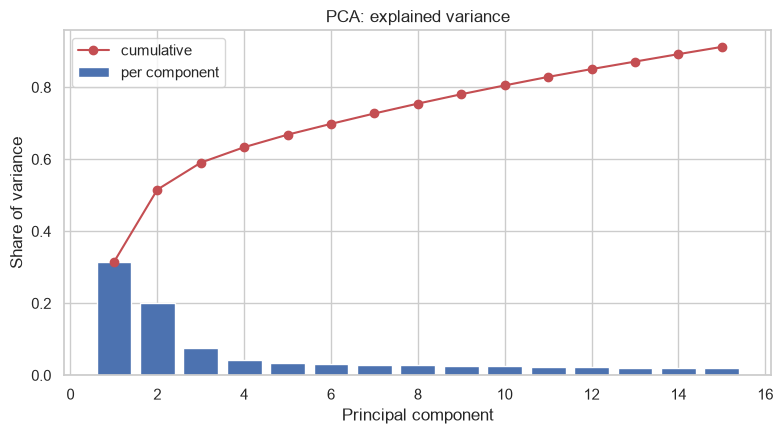

PC1 top loadings


num__MonthlyCharges                        0.49
num__TotalCharges                          0.48
num__tenure                                0.33
cat__StreamingMovies_Yes                   0.17
cat__StreamingTV_Yes                       0.17
cat__OnlineSecurity_No internet service   -0.17
Name: PC1, dtype: float64

PC2 top loadings


num__tenure                     0.49
num__TotalCharges               0.29
cat__Contract_Month-to-month   -0.25
cat__TechSupport_No            -0.23
cat__OnlineSecurity_No         -0.22
cat__DeviceProtection_No       -0.22
Name: PC2, dtype: float64

In [3]:
pca = fit_pca(Z)
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
n80 = int(np.argmax(cum >= 0.80)) + 1
n90 = int(np.argmax(cum >= 0.90)) + 1
print(f'PC1 {evr[0]:.1%}, PC2 {evr[1]:.1%}, first two {cum[1]:.1%}; 80% needs {n80} components, 90% needs {n90}')
k = 15
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(range(1, k + 1), evr[:k], color='#4C72B0', label='per component')
ax.plot(range(1, k + 1), cum[:k], marker='o', color='#C44E52', label='cumulative')
ax.set_title('PCA: explained variance')
ax.set_xlabel('Principal component')
ax.set_ylabel('Share of variance')
ax.legend()
save_fig('23_pca_explained_variance')
plt.show()

loadings = pd.DataFrame(pca.components_[:2].T, index=feature_names, columns=['PC1', 'PC2'])
for pc in ['PC1', 'PC2']:
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(6)
    print(pc, 'top loadings')
    display(top.round(2))

**Result:** PC1 explains 31.4% and PC2 20.1% of the variance (51.6% together); 10 components are needed for 80% and 15 for 90%.

PC1 is spending and service level (`MonthlyCharges`, `TotalCharges`, streaming services; negative for no internet). PC2 is commitment (`tenure` positive; month-to-month and missing support services negative). The 2D plot shows about half of the structure, so it is a visual aid, not the clustering input.

## 3. Choosing K

K is limited to 3 or 4 (as planned). Rule: take the one with the higher silhouette score, provided the clusters are stable across random starts (ARI between two seeds).

,inertia,silhouette,stability_ari
k,,,
2,44598.237,0.274,1.000
3,34281.047,0.274,0.999
4,31446.867,0.226,0.997
5,29566.832,0.208,1.000
6,28238.492,0.170,0.999
7,27061.487,0.153,0.967
8,26258.347,0.137,0.986


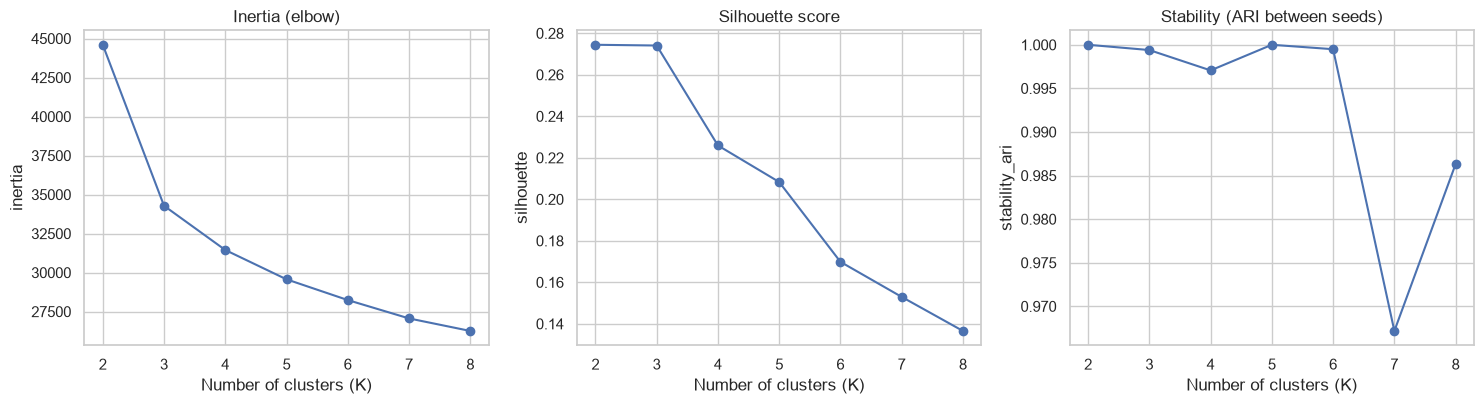

In [4]:
scan = scan_k(Z, ks=range(2, 9))
display(scan.round(3))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col, title in zip(axes, ['inertia', 'silhouette', 'stability_ari'],['Inertia (elbow)', 'Silhouette score', 'Stability (ARI between seeds)']):
    ax.plot(scan.index, scan[col], marker='o', color='#4C72B0')
    ax.set_title(title)
    ax.set_xlabel('Number of clusters (K)')
    ax.set_ylabel(col)
save_fig('24_kmeans_k_scan')
plt.show()

**Result:** the silhouette score is 0.274 for K=2 and K=3 and falls to 0.226 at K=4. Stability is near 1.0 up to K=6 (ARI >= 0.997), so the segments do not depend on the random start. The structure is moderate (silhouette below 0.3), not sharp.

**Choice:** K=3. K=4 is shown later as a finer view.

## 4. Three segments (K=3)

Cluster numbers are sorted by churn rate (0 = lowest), so they do not change between runs.

In [5]:
km3 = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(Z)
labels3 = relabel_by_churn(km3.labels_, y_train)
prof3 = cluster_profile(X_train, y_train, labels3, num_cols, cat_cols)
prof3.round(2).to_csv(REPORT_DIR / 'cluster_profiles_k3.csv')

display(prof3[['size', 'share_%', 'churn_rate_%', 'tenure_mean','MonthlyCharges_mean', 'TotalCharges_mean']].round(1))
display(prof3[['Contract_top', 'InternetService_top', 'PaymentMethod_top','TechSupport_top', 'OnlineSecurity_top', 'SeniorCitizen_top','Partner_top']])

,size,share_%,churn_rate_%,tenure_mean,MonthlyCharges_mean,TotalCharges_mean
cluster,,,,,,
0,1214,21.5,7.2,30.2,21.1,657.1
1,1932,34.3,15.6,56.7,88.8,5025.6
2,2488,44.2,44.5,14.8,67.7,983.6


,Contract_top,InternetService_top,PaymentMethod_top,TechSupport_top,OnlineSecurity_top,SeniorCitizen_top,Partner_top
cluster,,,,,,,
0,Two year (42%),No (100%),Mailed check (49%),No internet service (100%),No internet service (100%),0 (97%),No (51%)
1,Two year (41%),Fiber optic (61%),Bank transfer (automatic) (33%),Yes (58%),Yes (54%),0 (80%),Yes (68%)
2,Month-to-month (88%),Fiber optic (52%),Electronic check (50%),No (78%),No (77%),0 (80%),No (67%)


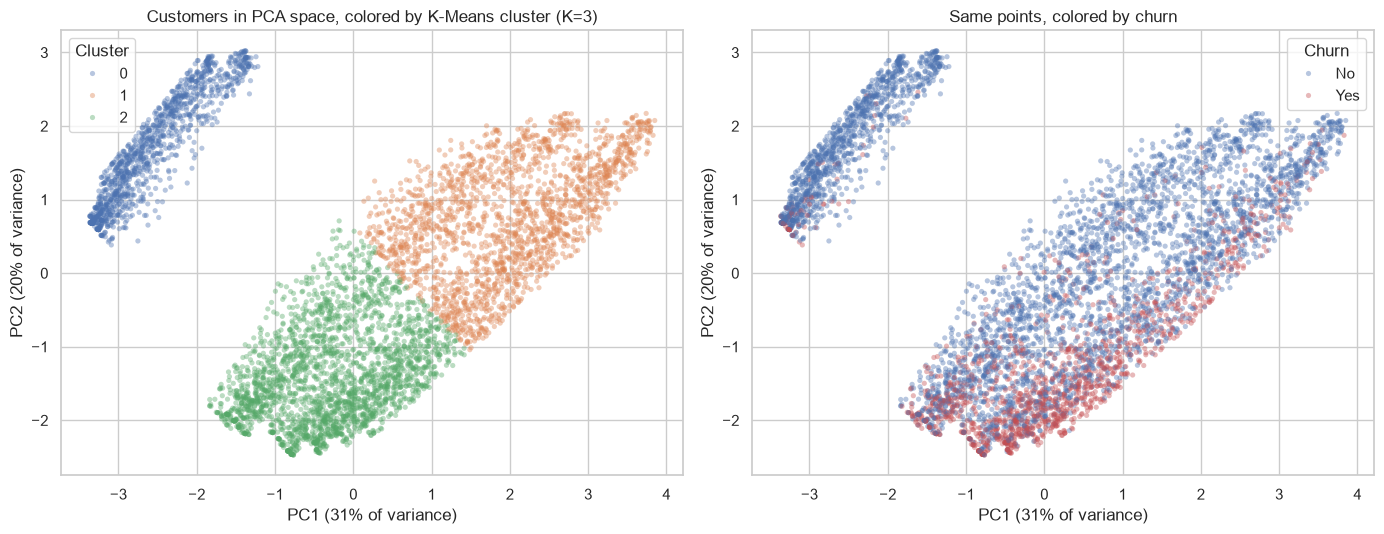

In [6]:
Z2 = pca.transform(Z)[:, :2]
plot_df = pd.DataFrame({'PC1': Z2[:, 0], 'PC2': Z2[:, 1],'Cluster': labels3.astype(str),'Churn': np.where(y_train == 1, 'Yes', 'No')})

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=plot_df, x='PC1', y='PC2', hue='Cluster',hue_order=['0', '1', '2'], alpha=0.4, s=14, linewidth=0, ax=axes[0])
axes[0].set_title('Customers in PCA space, colored by K-Means cluster (K=3)')
sns.scatterplot(data=plot_df.sample(frac=1, random_state=RANDOM_STATE), x='PC1', y='PC2',hue='Churn', hue_order=['No', 'Yes'],palette={'No': '#4C72B0', 'Yes': '#C44E52'},alpha=0.4, s=14, linewidth=0, ax=axes[1])
axes[1].set_title('Same points, colored by churn')
for ax in axes:
    ax.set_xlabel(f'PC1 ({evr[0]:.0%} of variance)')
    ax.set_ylabel(f'PC2 ({evr[1]:.0%} of variance)')
save_fig('25_pca_clusters_and_churn')
plt.show()

**Result:** the clusters occupy different regions of the PCA plane, and churn concentrates in the low-PC2 (low commitment) region, which is cluster 2.

| Cluster | Name | Share | Churn | Profile |
|---|---|---|---|---|
| 0 | Phone-only, low bill | 21.5% | 7.2% | No internet, ~$21 per month, tenure ~30 months, often a two-year contract (42%), mailed check |
| 1 | Loyal full-service | 34.3% | 15.6% | Tenure ~57 months, ~$89 per month, fiber 61%, two-year contract 41%, usually has tech support (58%) and online security (54%) |
| 2 | New, month-to-month | 44.2% | 44.5% | Tenure ~15 months, ~$68 per month, month-to-month 88%, no tech support 78%, electronic check 50% |

Ideas to test (not proven effects): for cluster 2, onboarding, offers for yearly contracts and moving customers from electronic check to autopay; for cluster 1, protect service quality and reward loyalty; cluster 0 needs no campaign (low risk, low revenue).

## 5. Four segments (K=4), a finer view

,size,share_%,churn_rate_%,tenure_mean,MonthlyCharges_mean,TotalCharges_mean
cluster,,,,,,
0,1214,21.5,7.2,30.2,21.1,657.1
1,1613,28.6,13.5,59.6,91.1,5419.1
2,1329,23.6,25.3,20.2,50.9,1049.6
3,1478,26.2,57.8,15.8,84.9,1367.3


,Contract_top,InternetService_top,PaymentMethod_top,TechSupport_top,OnlineSecurity_top
cluster,,,,,
0,Two year (42%),No (100%),Mailed check (49%),No internet service (100%),No internet service (100%)
1,Two year (46%),Fiber optic (63%),Bank transfer (automatic) (34%),Yes (60%),Yes (57%)
2,Month-to-month (71%),DSL (100%),Electronic check (33%),No (64%),No (62%)
3,Month-to-month (96%),Fiber optic (99%),Electronic check (63%),No (86%),No (87%)


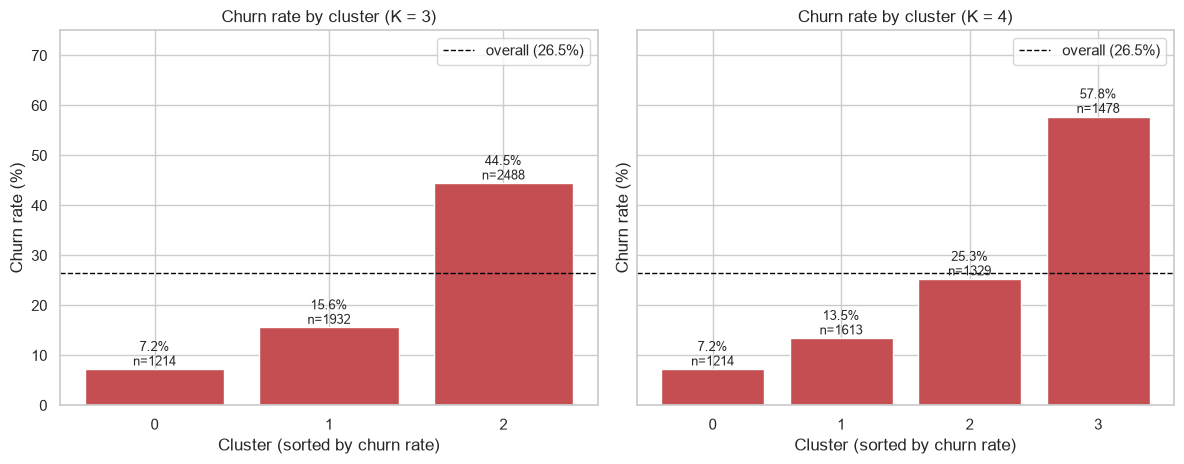

In [7]:
km4 = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(Z)
labels4 = relabel_by_churn(km4.labels_, y_train)

prof4 = cluster_profile(X_train, y_train, labels4, num_cols, cat_cols)
prof4.round(2).to_csv(REPORT_DIR / 'cluster_profiles_k4.csv')

display(prof4[['size', 'share_%', 'churn_rate_%', 'tenure_mean','MonthlyCharges_mean', 'TotalCharges_mean']].round(1))
display(prof4[['Contract_top', 'InternetService_top', 'PaymentMethod_top','TechSupport_top', 'OnlineSecurity_top']])

overall = y_train.mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, prof, title in zip(axes, [prof3, prof4], ['K = 3', 'K = 4']):
    bars = ax.bar(prof.index.astype(str), prof['churn_rate_%'], color='#C44E52')
    ax.bar_label(bars, labels=[f'{r:.1f}%\nn={int(n)}'for r, n in zip(prof['churn_rate_%'], prof['size'])],fontsize=9)
    ax.axhline(overall, color='black', linestyle='--', linewidth=1,label=f'overall ({overall:.1f}%)')
    ax.set_title(f'Churn rate by cluster ({title})')
    ax.set_xlabel('Cluster (sorted by churn rate)')
    ax.set_ylabel('Churn rate (%)')
    ax.set_ylim(0, 75)
    ax.legend()
save_fig('26_churn_by_cluster')
plt.show()

**Result:** K=4 keeps the "phone-only" (7.2%) and "loyal" (13.5%) groups and splits the month-to-month customers in two:
- Cluster 2 (23.6%): DSL, month-to-month, ~$51 per month, churn 25.3%, about the overall rate.
- Cluster 3 (26.2%): fiber (99%), month-to-month (96%), ~$85 per month, tenure ~16 months, churn **57.8%**, more than twice the overall 26.5%.

The silhouette is lower (0.226), so the borders are less clean, but cluster 3 is where retention effort has the most to gain.